# Analisi del Sentiment nei Tweet

In questo progetto affronteremo un compito di Sentiment Analysis, ovvero la classificazione automatica dei tweet in tre categorie:
- **Positivo**
- **Negativo**
- **Neutro**

L'obiettivo sarà costruire un **classificatore** in grado di prevedere il sentimento di un tweet, partendo da un dataset etichettato.

Il progetto sarà suddiviso nelle seguenti fasi:
1. **Esplorazione del dataset** per capire la distribuzione delle classi e la qualità dei dati.
2. **Preprocessing del testo** per rimuovere rumore e ottenere una rappresentazione pulita.
3. **Analisi esplorativa** delle parole più frequenti per ciascuna classe.
4. **Trasformazione dei testi in feature numeriche** tramite la tecnica TF-IDF.
5. **Addestramento di modelli di Machine Learning**
6. **Valutazione delle prestazioni** tramite metriche di classificazione e matrice di confusione.

# 1. Caricamento dei dati
Abbiamo caricato il dataset usando la libreria pandas e visualizzato le prime righe del dataset.


In [171]:
# Importiamo le librerie necessarie
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Carichiamo il dataset
df = pd.read_csv('Tweets_INTEGRALE.csv', encoding='utf-8')


# Visualizziamo le prime righe del dataset
df.head()

,tweet,sentiment
0,The event starts at 5 PM.,neutral
1,I hate how this turned out.,negative
2,Fantastic experience!,positive
3,This is the worst thing ever!,negative
4,What a wonderful day!,positive


# 2. Prima ispezione del dataset

In [172]:
# Dimensioni del dataset
print(f"Il dataset contiene {df.shape[0]} righe e {df.shape[1]} colonne.")

# Controlliamo il nome delle colonne
print("Nomi delle colonne:", df.columns.tolist())

Il dataset contiene 20947 righe e 2 colonne.
Nomi delle colonne: ['tweet', 'sentiment']


In [173]:
# Stampa tutti i possibili valori unici per la colonna 'sentiment'
print("Valori unici nella colonna 'sentiment':", df['sentiment'].unique())

Valori unici nella colonna 'sentiment': ['neutral' 'negative' 'positive']



Valori nulli per colonna:
tweet        0
sentiment    0
dtype: int64

Distribuzione delle etichette:
sentiment
neutral     8568
positive    6401
negative    5978
Name: count, dtype: int64


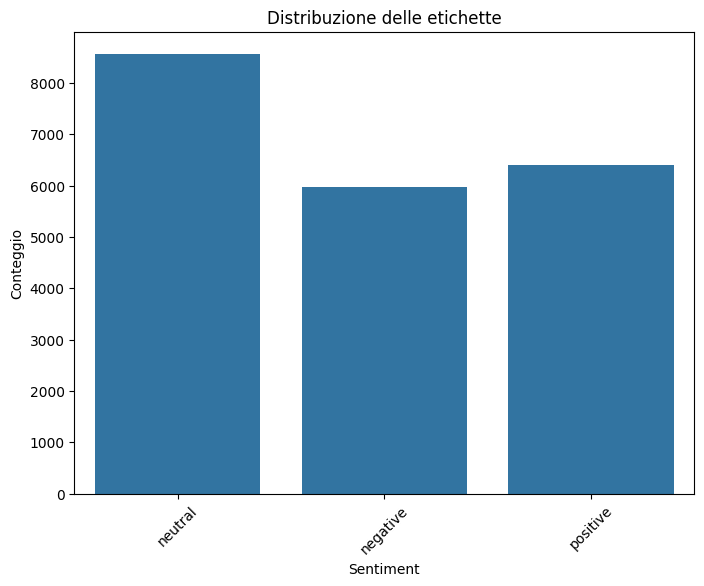

In [174]:
# Controlliamo se ci sono valori nulli
print("\nValori nulli per colonna:")
print(df.isnull().sum())

# Controlliamo la distribuzione delle etichette
print("\nDistribuzione delle etichette:")
print(df['sentiment'].value_counts())

# Faccio un istogramma per vedere la distribuzione delle etichette
plt.figure(figsize=(8, 6))
sns.countplot(x='sentiment', data=df)
plt.title('Distribuzione delle etichette')
plt.xlabel('Sentiment')
plt.ylabel('Conteggio')
plt.xticks(rotation=45)
plt.show()


Lunghezza media dei tweet per sentiment:
sentiment
negative    12.450151
neutral     11.154295
positive    12.055304
Name: length, dtype: float64


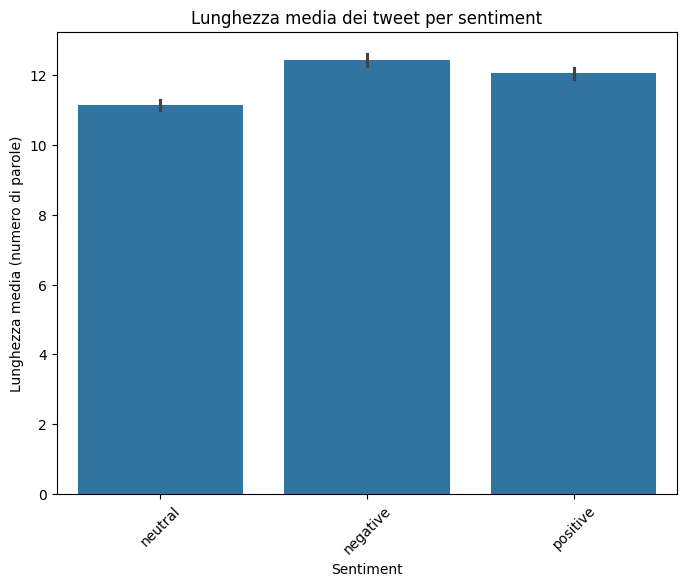

In [175]:
# stampa la lunghezza media dei tweet per sentiment
print("\nLunghezza media dei tweet per sentiment:")
df['length'] = df['tweet'].apply(lambda x: len(x.split()))   
print(df.groupby('sentiment')['length'].mean())

# Visualizza la lunghezza media dei tweet per sentiment
plt.figure(figsize=(8, 6))
sns.barplot(x='sentiment', y='length', data=df)
plt.title('Lunghezza media dei tweet per sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Lunghezza media (numero di parole)')
plt.xticks(rotation=45)
plt.show()  

# 3. Preprocessing dei Tweet

In [176]:
import re
import emoji
    
def clean_text(text, keep_emojis=True):
    if pd.isna(text):
        return ""

    text = text.lower()  # normalizzazione case
    
    # Rimuove URL, menzioni e hashtag
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    
    # Rimuove menzioni e hashtag, considerando che alcuni potrebbero essere scritti con uno spazio tra @ e il nome
    text = re.sub(r'@\w+|#\w+', '', text)
    
    # Gestisce caratteri ripetuti (sooooo -> so)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    
    # Rimuove caratteri speciali ma mantiene lettere, numeri, spazi e underscore
    text = re.sub(r'[^\w\s]', ' ', text)
    
    # Rimuove singoli caratteri TRANNE "i" e "a" che sono importanti
    text = re.sub(r'\b(?![ia]\b)\w\b', '', text)

    # Se si vogliono mantenere le emoji
    if keep_emojis:
        text = emoji.demojize(text, language='it')
        text = re.sub(r':', ' ', text)
        text = re.sub(r'[^\w\s]', '', text)
    else:
        text = emoji.replace_emoji(text, replace='')
        text = re.sub(r'[^\w\s]', '', text)

    # Rimuove spazi multipli
    text = re.sub(r'\s+', ' ', text).strip()
    return text



In [177]:
# Applichiamo la funzione di pulizia al testo del dataset
df['cleaned_text'] = df['tweet'].apply(clean_text)
df.head()

,tweet,sentiment,length,cleaned_text
0,The event starts at 5 PM.,neutral,6,the event starts at pm
1,I hate how this turned out.,negative,6,i hate how this turned out
2,Fantastic experience!,positive,2,fantastic experience
3,This is the worst thing ever!,negative,6,this is the worst thing ever
4,What a wonderful day!,positive,4,what a wonderful day


## 3.1 Label Encoder

In [178]:
# Mappiamo le etichette in numeri
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['label'] = le.fit_transform(df['sentiment'])

In [179]:
# Stampa delle etichette originali e i valori numerici corrispondenti
print("\nEtichette originali e codificate:")
for original, encoded in zip(le.classes_, range(len(le.classes_))):
    print(f"{original} -> {encoded}")
    

# Distribuzione dei label numerici
print("\nDistribuzione delle etichette codificate:")
print(df['label'].value_counts())


Etichette originali e codificate:
negative -> 0
neutral -> 1
positive -> 2

Distribuzione delle etichette codificate:
label
1    8568
2    6401
0    5978
Name: count, dtype: int64


# 4 Analisi visiva delle WordCloud per ciascun sentimento

Le WordCloud offrono una rappresentazione grafica delle parole più frequenti in ciascuna classe di sentimento, aiutandoci a individuare i termini più rappresentativi del linguaggio usato dagli utenti nei tweet.

- **Classe "neutral"**  
  Le parole più comuni risultano legate ad attività quotidiane o informative, come "working", "home", "event starts", "today". Non emergono particolari emozioni o giudizi, il che è coerente con un tono neutro.

- **Classe "negative"**  
  In questa classe emergono parole con carica negativa come "disappointed", "hate", "worst", "terrible decision", "sick". Questi termini esprimono chiaramente sentimenti di insoddisfazione o malessere, rendendo il tono del messaggio facilmente riconoscibile come negativo.

- **Classe "positive"**  
  La WordCloud dei tweet positivi evidenzia parole come "loved", "happy", "fantastic experience", "great job", "wonderful day". Sono tutti termini che trasmettono emozioni positive, gratitudine o soddisfazione, perfettamente in linea con l'etichetta della classe.


In [180]:
# Breve analisi esplrorativa delle parole piu comuni e word cloud delle classi
from wordcloud import WordCloud

def plot_wordcloud(text, title):
    """Genera e visualizza una word cloud"""
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title)
    plt.show()


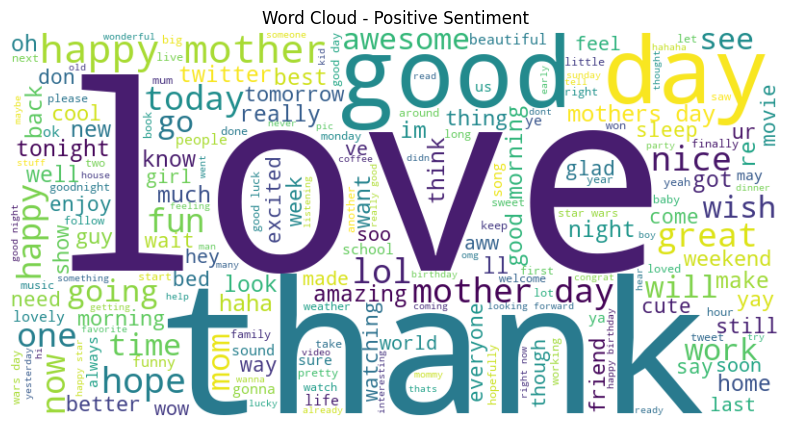

In [181]:
plot_wordcloud(" ".join(df[df['sentiment'] == 'positive']['cleaned_text']), "Word Cloud - Positive Sentiment")

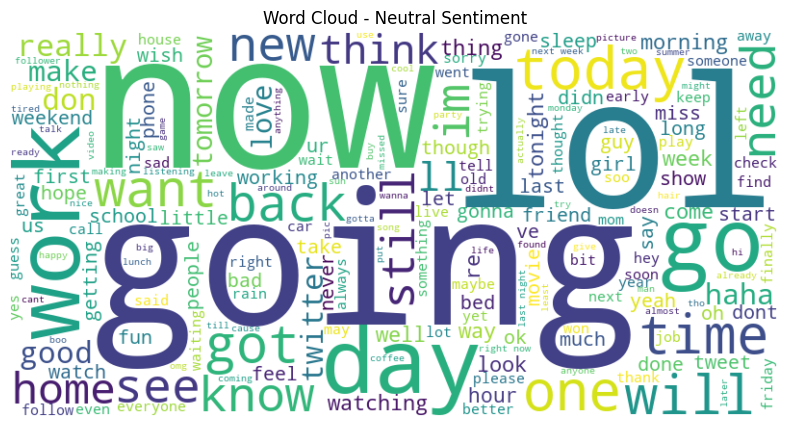

In [182]:
plot_wordcloud(" ".join(df[df['sentiment'] == 'neutral']['cleaned_text']), "Word Cloud - Neutral Sentiment")

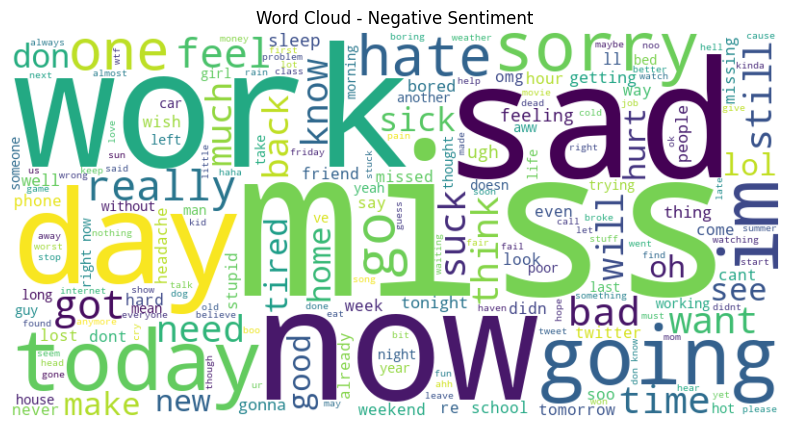

In [183]:
plot_wordcloud(" ".join(df[df['sentiment'] == 'negative']['cleaned_text']), "Word Cloud - Negative Sentiment")

# 5. Suddivisione del dataset in Training e Test Set

Prima di costruire la matrice TF-IDF, dividiamo il dataset in due parti:
- **Training Set** (80% dei dati), che useremo per addestrare il modello.
- **Test Set** (20% dei dati), che useremo per valutare le sue prestazioni.

In [184]:
# Importiamo il metodo per la divisione train/test
from sklearn.model_selection import train_test_split
import numpy as np

# Definiamo X e Y 
X = df['cleaned_text']
Y = df['label']

# Suddividiamo in train e test mantenendo la stessa distribuzione delle classi (stratify=y)
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, stratify=Y, random_state=4
)

# Verifica delle dimensioni
print(f"Training Set: {X_train.shape[0]} esempi")
print(f"Test Set: {X_test.shape[0]} esempi")


Training Set: 16757 esempi
Test Set: 4190 esempi


In [185]:
# Controlliamo la distribuzione delle etichette dopo la divisione
print("\nDistribuzione delle etichette nel training set:")
print(Y_train.value_counts())


Distribuzione delle etichette nel training set:
label
1    6854
2    5121
0    4782
Name: count, dtype: int64


## 5.1 Data Augmentation

In [186]:
import nlpaug.augmenter.word as naw

augmenter = naw.SynonymAug(aug_src='wordnet', lang='eng', aug_p=0.3)

In [187]:
import tqdm
import pandas as pd

def balance_classes_split(x_train, y_train, target_class, n_samples, le, seed=1234):
    """ 
    Bilancia le classi applicando data augmentation su X e y già separati
    
    Args:
        X_train: Serie con i testi
        y_train: Serie con le etichette encoded
        target_class: classe da bilanciare (etichetta encoded, es: 0, 1, 2)
        n_samples: numero target di campioni per classe
        le: LabelEncoder già fittato
        seed: seed per riproducibilità
    """
    np.random.seed(seed)
    
    # Trova gli indici della classe target
    target_indices = np.where(y_train == target_class)[0]
    
    # Se il numero di campioni della classe target è già sufficiente, ritorna i dati originali
    if len(target_indices) >= n_samples:
        return x_train, y_train
    
    n_to_generate = n_samples - len(target_indices)
    
    # Calcola pesi basati sulla lunghezza del testo
    target_texts = x_train.iloc[target_indices]
    text_lengths = target_texts.str.len()
    weights = text_lengths / text_lengths.sum()
    
    # Genera gli indici campione
    sample_indices = np.random.choice(target_indices, size=n_to_generate, p=weights)
    
    # Liste per i nuovi dati
    synthetic_texts = []
    synthetic_labels = []
    
    # Applica data augmentation
    class_name = le.inverse_transform([target_class])[0]
    for sample_idx in tqdm.tqdm(sample_indices, desc=f"Augmenting {class_name}"):
        text = x_train.iloc[sample_idx]
        
        try:
            aug_text = str(augmenter.augment(text))
            
            # Controlli di qualità
            if aug_text and aug_text != text and len(aug_text.split()) > 2:
                synthetic_texts.append(aug_text)
                synthetic_labels.append(target_class)
        except Exception as e:
            print(f"Augmentation failed for: {text[:50]}... Error: {e}")
            synthetic_texts.append(text)
            synthetic_labels.append(target_class)
    
    # Crea il DataFrame sintetico
    x_combined = pd.concat([x_train, pd.Series(synthetic_texts, name='cleaned_text')], ignore_index=True)
    y_combined = pd.concat([y_train, pd.Series(synthetic_labels, name='label')], ignore_index=True)
    
    return x_combined, y_combined

In [188]:
X_train_balanced = X_train.copy()
Y_train_balanced = Y_train.copy()

# Bilancia le classi per ogni classe
for class_label in le.transform(le.classes_):
    print(f"Bilanciamento per la classe: {le.inverse_transform([class_label])[0]}")
    X_train_balanced, Y_train_balanced = balance_classes_split( X_train_balanced, Y_train_balanced, class_label, 9000, le)

# Verifica la distribuzione delle etichette dopo il bilanciamento
print("\nDistribuzione delle etichette nel training set bilanciato:")
print(Y_train_balanced.value_counts())

Bilanciamento per la classe: negative


Augmenting negative: 100%|██████████| 4218/4218 [00:04<00:00, 858.93it/s]


Bilanciamento per la classe: neutral


Augmenting neutral: 100%|██████████| 2146/2146 [00:02<00:00, 873.08it/s]


Bilanciamento per la classe: positive


Augmenting positive: 100%|██████████| 3879/3879 [00:05<00:00, 764.70it/s]


Distribuzione delle etichette nel training set bilanciato:
label
0    8991
1    8983
2    8982
Name: count, dtype: int64


In [189]:
print(len(X_train_balanced), len(Y_train_balanced))

26956 26956


# 6. Costruzione della matrice TF-IDF

Ora trasformiamo i testi in numeri utilizzando la tecnica TF-IDF (Term Frequency - Inverse Document Frequency).
Creeremo il vocabolario e calcoleremo i pesi delle parole **solo sui dati di training**, per poi applicarli anche ai dati di test, mantenendo così una corretta separazione tra fase di apprendimento e valutazione.


In [190]:
# Importiamo il vettorizzatore TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

# Inizializziamo il vettorizzatore TF-IDF
vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 3),  # Considera sia unigrammi che bigrammi
    lowercase=True, # Converte tutto in minuscolo
)

X_train_tfidf = vectorizer.fit_transform(X_train_balanced)
X_test_tfidf = vectorizer.transform(X_test)

# Verifica delle dimensioni delle matrici
print("Matrice TF-IDF di Training:", X_train_tfidf.shape)
print("Matrice TF-IDF di Test    :", X_test_tfidf.shape)

Matrice TF-IDF di Training: (26956, 5000)
Matrice TF-IDF di Test    : (4190, 5000)


# 7. Il Modello

In [191]:
from torch import nn

class SoftmaxClassifier(nn.Module):
    def __init__(self, input_dim, output_dim):
        """
        Inizializza il classificatore softmax con Batch Normalization.

        Args:
            input_dim: Dimensione dell'input (numero di features TF-IDF)
            output_dim: Numero di classi (3 per negativo, neutro, positivo)
        """
        super(SoftmaxClassifier, self).__init__()

        self.model = nn.Sequential(

            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),  # Batch Normalization per stabilizzare l'addestramento
            nn.ReLU(),
            nn.Dropout(0.4),  # Dropout più alto per TF-IDF per evitare overfitting
            
            
            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        return self.model(x)



In [192]:
#%reload_ext tensorboard

In [193]:
#%tensorboard --logdir logs --host localhost --port 6012

In [194]:
# Converte direttamente TF-IDF sparse in tensori densi
import torch

X_train_tensor = torch.FloatTensor(X_train_tfidf.toarray())
Y_train_tensor = torch.LongTensor(Y_train_balanced.values)
X_test_tensor = torch.FloatTensor(X_test_tfidf.toarray())
Y_test_tensor = torch.LongTensor(Y_test.values)

print("Dimensioni dei tensori:" )
print("X_train_tensor:", X_train_tensor.shape)
print("Y_train_tensor:", Y_train_tensor.shape)
print("X_test_tensor:", X_test_tensor.shape)    
print("Y_test_tensor:", Y_test_tensor.shape)


Dimensioni dei tensori:
X_train_tensor: torch.Size([26956, 5000])
Y_train_tensor: torch.Size([26956])
X_test_tensor: torch.Size([4190, 5000])
Y_test_tensor: torch.Size([4190])


## 7.1 Addestramento del modello

In [195]:
from torch.optim import Adam, SGD
from torch.utils.tensorboard import SummaryWriter
from sklearn.metrics import accuracy_score
import tqdm

writer = SummaryWriter('logs/softmax_classifier_v3_27000')

'''
Soluzione migliore:
input->64->3
lr = 0.001
weight_decay = 5e-3
epochs = 150
patience = 10 
dropout = 0.4
scheduler_factor = 0.4
ngram_range = (1, 3)
features = 5000 o 2000
'''

lr = 0.001
epochs = 150
patience = 10  # Numero di epoche senza miglioramento per fermare il training
best_loss = float('inf')
epochs_no_improve = 0

model = SoftmaxClassifier(X_train_tensor.shape[1], len(Y_train.unique())) 
criterion = nn.CrossEntropyLoss()  # Usa i pesi bilanciati
optimizer = Adam(model.parameters(), lr=lr, weight_decay=5e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.4, patience=5)

test_losses = []

for e in tqdm.tqdm(range(epochs), desc="Training Softmax Classifier"):
    model.train()
    out = model(X_train_tensor)
    loss = criterion(out, Y_train_tensor)

    loss.backward()
    optimizer.step()
    optimizer.zero_grad()

    with torch.no_grad():
        preds_train = out.argmax(dim=1)
        train_acc = accuracy_score(Y_train_tensor.cpu(), preds_train.cpu())

    writer.add_scalar('Loss/train', loss.item(), e)
    writer.add_scalar('Accuracy/train', train_acc, e)

    # VALIDAZIONE
    model.eval()
    with torch.no_grad():
        test_out = model(X_test_tensor)
        test_loss = criterion(test_out, Y_test_tensor)
        preds_test = test_out.argmax(dim=1)
        test_acc = accuracy_score(Y_test_tensor.cpu(), preds_test.cpu())

    writer.add_scalar('Loss/test', test_loss.item(), e)
    writer.add_scalar('Accuracy/test', test_acc, e)
    test_losses.append(test_loss.item())

    scheduler.step(test_loss)

    # EARLY STOPPING
    if test_loss.item() < best_loss - 1e-4:
        best_loss = test_loss.item()
        epochs_no_improve = 0
        best_model_state = model.state_dict()
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping a epoch {e+1}")
            model.load_state_dict(best_model_state)
            break

print("Training completato!")

writer.close()


Training Softmax Classifier:  60%|██████    | 90/150 [00:40<00:26,  2.24it/s]

Early stopping a epoch 91
Training completato!


## 7.2 Valutazione del modello

In [196]:
# Stampa la matrice di confusione
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(y_true, y_pred, classes):
    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title('Matrice di Confusione')
    plt.xlabel('Predizioni')
    plt.ylabel('Reali')
    plt.show()

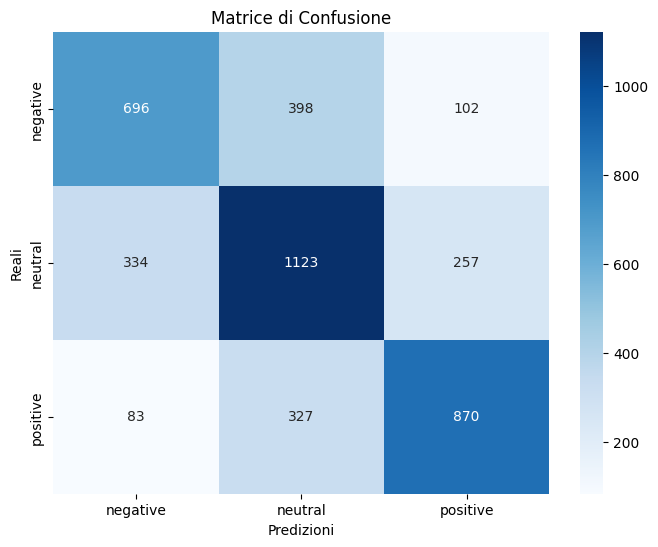

In [197]:
# Plottiamo i risultati del modello 1
preds_test = model(X_test_tensor).max(1)[1]
plot_confusion_matrix(Y_test_tensor.numpy(), preds_test.numpy(), le.classes_)

In [198]:
# Calcola f1-score, precision e recall di un determinato modello
from sklearn.metrics import f1_score, precision_score, recall_score

def calculate_metrics(y_true, y_pred):
    f1 = f1_score(y_true, y_pred, average='weighted')
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    
    print(f"F1 Score: {f1:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")

In [199]:
# Stampiamo le metriche per il modello 1
calculate_metrics(Y_test_tensor.numpy(), preds_test.numpy())


F1 Score: 0.6419
Precision: 0.6433
Recall: 0.6418
Accuracy: 0.6418


In [200]:
# Funzione per visualizzare la curva ROC
from sklearn.metrics import roc_curve, auc
def plot_roc_curve(y_true, y_scores, classes):
    """Visualizza la curva ROC per ogni classe."""
    plt.figure(figsize=(10, 8))
    
    for i, class_name in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_true == i, y_scores[:, i])
        plt.plot(fpr, tpr, label=f'ROC curve {class_name} (area = {auc(fpr, tpr):.2f})')
    
    plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Curva ROC per ogni classe')
    plt.legend(loc='lower right')
    plt.show()

In [201]:
# Funzione per visuallizare la curva precision-recall
from sklearn.metrics import precision_recall_curve

def plot_precision_recall_curve(y_true, y_scores, classes):
    """Visualizza la curva Precision-Recall per ogni classe."""
    plt.figure(figsize=(10, 8))
    
    for i, class_name in enumerate(classes):
        precision, recall, _ = precision_recall_curve(y_true == i, y_scores[:, i])
        plt.plot(recall, precision, label=f'Precision-Recall curve {class_name}, area = {auc(recall, precision):.2f})')
    
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Curva Precision-Recall per ogni classe')
    plt.legend(loc='lower left')
    plt.show()

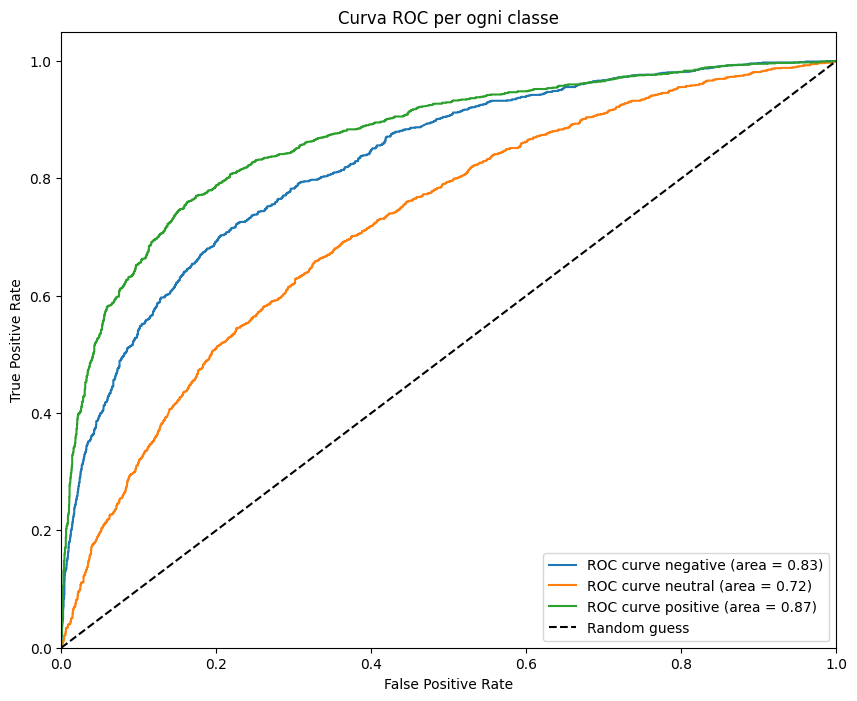

In [202]:
plot_roc_curve(Y_test_tensor.numpy(), model(X_test_tensor).detach().numpy(), le.classes_)

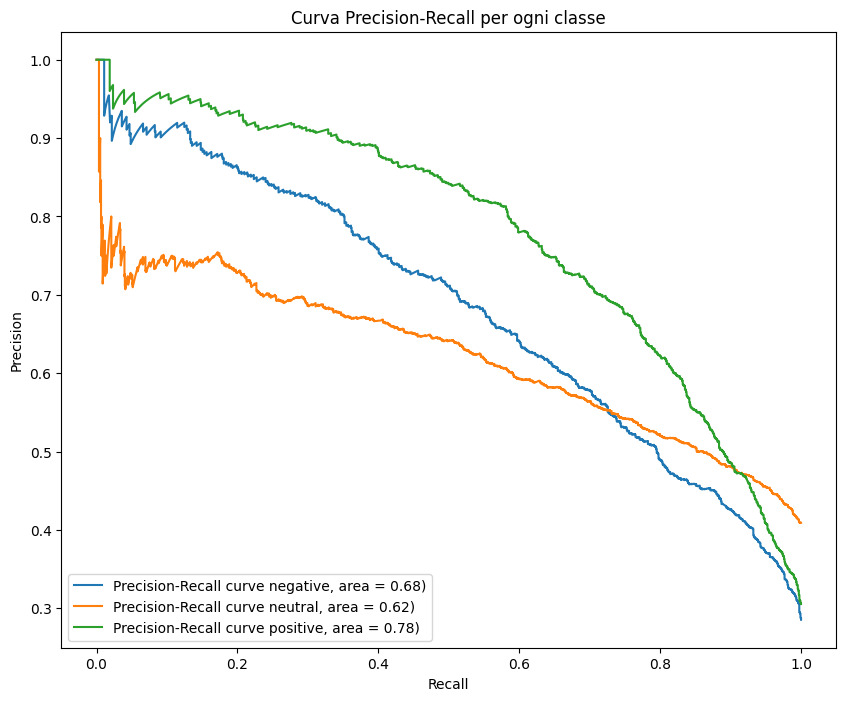

In [203]:
plot_precision_recall_curve(Y_test_tensor.numpy(), model(X_test_tensor).detach().numpy(), le.classes_)

# 8. (EXTRA per sentiment.py) 
Salvataggio del vettorizzatore, label encoder e del modello per successivo utilizzo nello script "sentiment.py"

In [204]:
import joblib
import torch

# Salva vettorizzatore e label encoder
joblib.dump(vectorizer, "vectorizer.pkl")
joblib.dump(le, "label_encoder.pkl")

# Salva modello
torch.save(model.state_dict(), "model.pth")
